In [1]:
import sys
from pathlib import Path

# 获取当前工作目录
cwd = Path.cwd().resolve()

# 自动确定项目根目录
project_root = cwd if (cwd / "src").is_dir() else cwd.parent

# 检查实际模型路径
model_path = project_root / "src" / "models" / "dncnn.py"

assert model_path.is_file(), f"模型文件不存在：{model_path}"

# 将项目根目录加入 Python 搜索路径
sys.path.insert(0, str(project_root))

# 导入模型和数据集
from src.models.dncnn import DnCNN
from src.datasets.sidd_dataset import SIDDDataset

print("项目根目录：", project_root)
print("DnCNN 导入成功！")
print("SIDDDataset 导入成功！")

项目根目录： D:\CodeRepository\graduation‑design
DnCNN 导入成功！
SIDDDataset 导入成功！


In [2]:
import torch
import math
from torch.utils.data import DataLoader

# 1. 选择设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. 创建 DnCNN 模型
model = DnCNN(
    in_channels=3,
    features=64,
    depth=20
).to(device)

# 3. 加载第一次训练保存的最佳权重
weight_path = project_root / "checkpoints" / "dncnn_sidd_best.pth"

state_dict = torch.load(
    weight_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()

print("最佳模型加载成功！")

# 4. 加载 SIDD 验证集
val_dataset = SIDDDataset(split="val")

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# 5. 记录每张图像的 PSNR
noisy_psnr_list = []
denoised_psnr_list = []

with torch.no_grad():

    for idx, (noisy, gt) in enumerate(val_loader, start=1):

        noisy = noisy.to(device)
        gt = gt.to(device)

        # DnCNN 去噪
        denoised = model(noisy).clamp(0, 1)

        # 原始噪声图像 PSNR
        mse_noisy = torch.mean((noisy - gt) ** 2).item()
        psnr_noisy = -10 * math.log10(max(mse_noisy, 1e-12))

        # 去噪后图像 PSNR
        mse_denoised = torch.mean((denoised - gt) ** 2).item()
        psnr_denoised = -10 * math.log10(max(mse_denoised, 1e-12))

        noisy_psnr_list.append(psnr_noisy)
        denoised_psnr_list.append(psnr_denoised)

        # 保存第一张样本，供下一块可视化
        if idx == 1:
            sample_noisy = noisy[0].cpu()
            sample_gt = gt[0].cpu()
            sample_denoised = denoised[0].cpu()

        if idx % 10 == 0 or idx == len(val_loader):
            print(f"已评价：{idx}/{len(val_loader)}")

# 6. 计算平均 PSNR
avg_noisy = sum(noisy_psnr_list) / len(noisy_psnr_list)
avg_denoised = sum(denoised_psnr_list) / len(denoised_psnr_list)

print("\n========== 评价结果 ==========")
print(f"原始 NOISY PSNR：{avg_noisy:.2f} dB")
print(f"DnCNN 去噪 PSNR：{avg_denoised:.2f} dB")
print(f"PSNR 提升：{avg_denoised - avg_noisy:+.2f} dB")

最佳模型加载成功！
已评价：10/46
已评价：20/46
已评价：30/46
已评价：40/46
已评价：46/46

========== 评价结果 ==========
原始 NOISY PSNR：29.33 dB
DnCNN 去噪 PSNR：28.98 dB
PSNR 提升：-0.35 dB


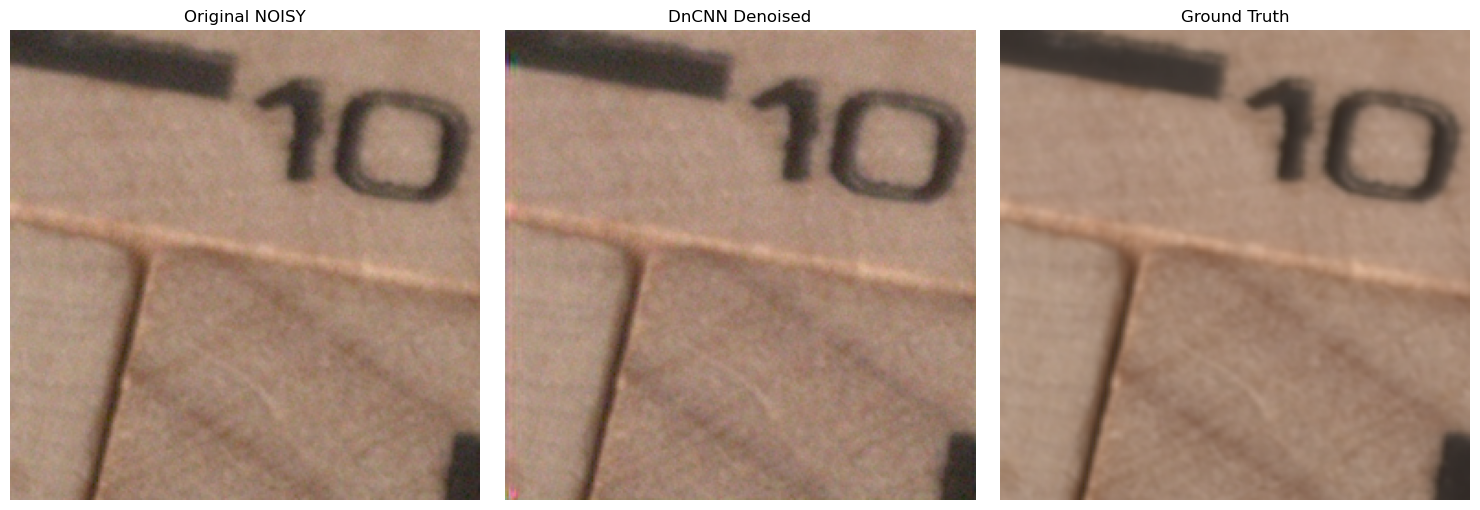

In [3]:
import matplotlib.pyplot as plt

# 将 Tensor 转为 matplotlib 可以显示的格式
noisy_img = sample_noisy.permute(1, 2, 0).numpy()
denoised_img = sample_denoised.permute(1, 2, 0).numpy()
gt_img = sample_gt.permute(1, 2, 0).numpy()

# 创建画布
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 原始噪声图像
axes[0].imshow(noisy_img)
axes[0].set_title("Original NOISY")
axes[0].axis("off")

# DnCNN 去噪图像
axes[1].imshow(denoised_img)
axes[1].set_title("DnCNN Denoised")
axes[1].axis("off")

# GT 干净图像
axes[2].imshow(gt_img)
axes[2].set_title("Ground Truth")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [4]:
# 计算每张验证图像的 PSNR 变化
improvements = [
    denoised - noisy
    for noisy, denoised in zip(
        noisy_psnr_list,
        denoised_psnr_list
    )
]

# 统计结果
better_count = sum(x > 0 for x in improvements)
worse_count = sum(x < 0 for x in improvements)
equal_count = sum(x == 0 for x in improvements)

print("验证图像总数：", len(improvements))
print("去噪后改善的图像：", better_count)
print("去噪后变差的图像：", worse_count)
print("PSNR 不变的图像：", equal_count)

print(f"最大 PSNR 提升：{max(improvements):+.2f} dB")
print(f"最大 PSNR 下降：{min(improvements):+.2f} dB")

验证图像总数： 46
去噪后改善的图像： 18
去噪后变差的图像： 28
PSNR 不变的图像： 0
最大 PSNR 提升：+0.21 dB
最大 PSNR 下降：-2.40 dB


PSNR 下降最严重的 5 张图像：
图像索引 20 | 原始：38.83 dB | 去噪：36.43 dB | 变化：-2.40 dB
图像索引 21 | 原始：38.80 dB | 去噪：36.42 dB | 变化：-2.38 dB
图像索引 41 | 原始：37.37 dB | 去噪：35.81 dB | 变化：-1.56 dB
图像索引 40 | 原始：37.29 dB | 去噪：35.76 dB | 变化：-1.53 dB
图像索引 1 | 原始：36.21 dB | 去噪：35.10 dB | 变化：-1.10 dB


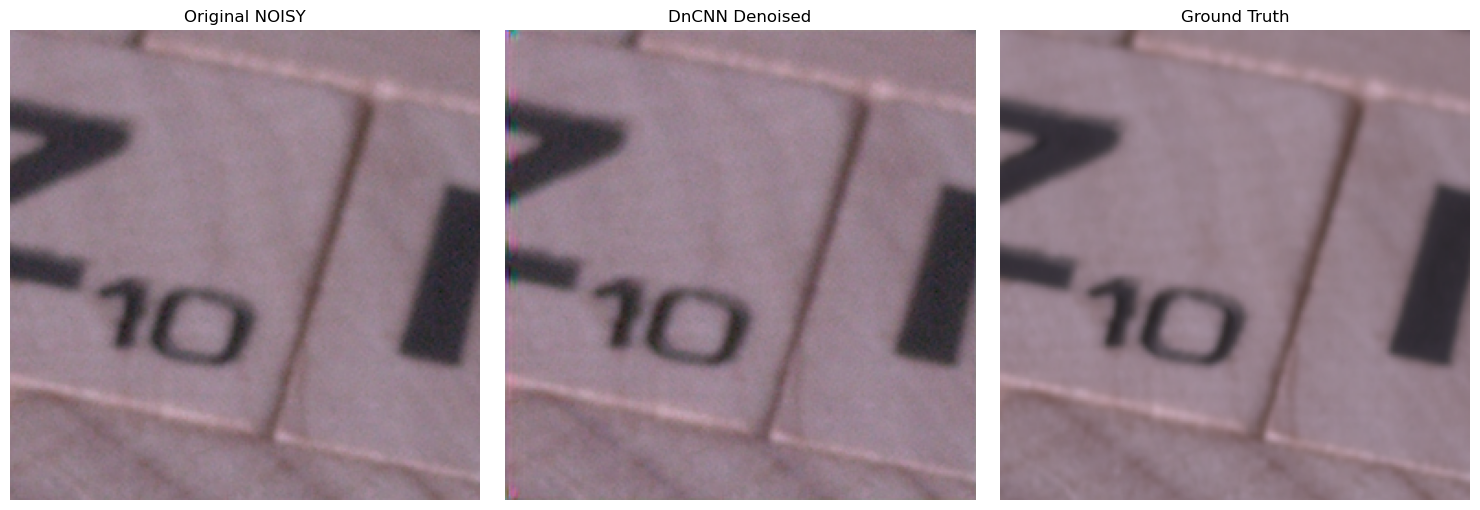

In [5]:
import matplotlib.pyplot as plt
import torch

# 找出 PSNR 下降最严重的 5 张图像
worst_indices = sorted(
    range(len(improvements)),
    key=lambda i: improvements[i]
)[:5]

print("PSNR 下降最严重的 5 张图像：")

for idx in worst_indices:
    print(
        f"图像索引 {idx} | "
        f"原始：{noisy_psnr_list[idx]:.2f} dB | "
        f"去噪：{denoised_psnr_list[idx]:.2f} dB | "
        f"变化：{improvements[idx]:+.2f} dB"
    )

# 取下降最严重的一张图像
idx = worst_indices[0]

noisy, gt = val_dataset[idx]

with torch.no_grad():
    denoised = model(
        noisy.unsqueeze(0).to(device)
    ).clamp(0, 1)[0].cpu()

# 显示图像
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [noisy, denoised, gt]
titles = ["Original NOISY", "DnCNN Denoised", "Ground Truth"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import torch
from src.datasets.sidd_dataset import SIDDDataset

# 验证集缓存目录
cache_dir = project_root / "data" / "cache" / "sidd_val"
cache_dir.mkdir(parents=True, exist_ok=True)

# 使用原来的 Dataset 生成固定中心裁剪
val_dataset = SIDDDataset(split="val")

for i in range(len(val_dataset)):
    noisy, gt = val_dataset[i]

    # 将 [0,1] 的 float32 转回原始 uint8 像素
    for name, tensor in [("noisy", noisy), ("gt", gt)]:
        array = (
            tensor.permute(1, 2, 0)
            .mul(255)
            .round()
            .to(torch.uint8)
            .numpy()
        )

        np.save(cache_dir / f"val_{i:04d}_{name}.npy", array)

print(f"验证集缓存生成完成：{len(val_dataset)} 对")
print("缓存位置：", cache_dir)

验证集缓存生成完成：46 对
缓存位置： D:\CodeRepository\graduation‑design\data\cache\sidd_val
